# `Материалы кафедры ММП факультета ВМК МГУ. Введение в эффективные системы глубокого обучения`

# `Лекция 05. Ускорение инференса: knowledge distillation, speculative decoding`

## `Занятие провел: Оганов Александр (tg: @welmud)`

## `Материалы составил: Оганов Александр (tg: @welmud)`

### `Москва, Осенний семестр 2026`

Источники:

- **Knowledge Distillation**: [Geoffrey Hinton et al., 2015](https://arxiv.org/abs/1503.02531), примерно 36000 цитирований

- **DINO**: [Mathilde Caron et al., 2021](https://arxiv.org/abs/2104.14294), примерно 13000 цитирований

- **DINOv2**: [Maxime Oquab et al., 2023](https://arxiv.org/abs/2304.07193), примерно 13000 цитирований

- **DINOv3**: [Oriane Siméoni et al., 2025](https://arxiv.org/abs/2508.10104), примерно 1600 цитирований

- **Averaging Weights Leads to Wider Optima and Better Generalization**: [Pavel Izmailov et al., 2018](https://arxiv.org/abs/1803.05407), примерно 2700 цитирований

- **Adversarial Diffusion Distillation**: [Axel Sauer et al., 2023](https://arxiv.org/abs/2311.17042), примерно 1100 цитирований

- **LD3**: [Vinh Tong et al., 2024](https://arxiv.org/abs/2405.15506), примерно 50 цитирований

- **GAS**: [Oganov et al., 2025](https://arxiv.org/abs/2510.17699), примерно 0 цитирований

- **MiniLLM**: [Yuxian Gu et al., 2023](https://arxiv.org/abs/2306.08543), примерно 1200 цитирований

- **Reinforcement Learning Textbook**: [Sergey Ivanov, 2022](https://arxiv.org/abs/2201.09746)

- **Speculative Decoding**: [Yaniv Leviathan et al., 2022](https://arxiv.org/abs/2211.17192), примерно 2500 цитирований

- **EAGLE**: [Yuhui Li et al., 2024](https://arxiv.org/abs/2401.15077), примерно 700 цитирований

- **EAGLE-2**: [Yuhui Li et al., 2024](https://arxiv.org/abs/2406.16858), примерно 400 цитирований

- **EAGLE-3**: [Yuhui Li et al., 2025](https://arxiv.org/abs/2503.01840), примерно 350 цитирований


- **DFlash**: [Jian Chen et al., 2026](https://arxiv.org/abs/2602.06036), примерно 100 цитирований

- [Блог-пост от Google Research про спекулятивный декодинг](https://research.google/blog/looking-back-at-speculative-decoding/)

- [Блог-пост от NVIDIA про современные подходы спекулятивного декодинга](https://developer.nvidia.com/blog/an-introduction-to-speculative-decoding-for-reducing-latency-in-ai-inference/)

- Подробно про модели DINO на лекции Оганова Александра [Deep learning 2, 2026](https://github.com/thecrazymage/DL2_HSE/tree/102338a347e777f16d1fd64f4e46c6ed732ae9b3/week_07)

- Материал вдохновлен лекцией Феоктистова Дмитрия [Введение в эффективные системы машинного обучения, 2024](https://github.com/mmp-efml/mmp-efml-2024-fall/blob/main/presentations/lec1_knowledge_distillation.pdf)


Дополнительные источники:

- [Zhiwei Hao et al., 2023](https://arxiv.org/abs/2310.19444), примерно 100 цитирований
- [Ying Zhang et al., 2017](https://arxiv.org/abs/1706.00384), примерно 2400 цитирований
- [Jang Hyun Cho, Bharath Hariharan, 2019](https://arxiv.org/abs/1910.01348), примерно 982 цитирований
- [Tommaso Furlanello et al., 2018](https://arxiv.org/abs/1805.04770), примерно 1390 цитирований
- [Samuel Stanton et al., 2021](https://arxiv.org/abs/2106.05945), примерно 322 цитирований
- [Samira Abnar et al., 2020](https://arxiv.org/abs/2006.00555), примерно 80 цитирований

Мы бы хотели не только обучать модели, но и применять. Желательно, применять эффективно на практике. Обсудим на занятии, как переносить "знания" из больших моделей в маленькие и что такое дистилляция. Затронем разные домены для дистилляции (классификаторы, LLM, генерация изображений, численные методы) и задачу, которую невозможно было бы решить без дистилляции.

Также изучим интересную технику "спекулятивный декодинг", которая позволяет  ускорить инференс LLM в разы, но потратив больше компьюта.

---

## Мотивация

Представим, вы обучили модель, вложили достаточно большое количество средств, но ваша основная цель &ndash; развернуть модель и дать к ней доступ. Чем меньше ресурсов потребляет модель при использовании, тем она быстрее и дешевле в использовании. Кроме того, отданные ресурсы на инференс будут зарезервированные и вы не сможете ими пользоваться.

## Distilling the Knowledge in a Neural Network (2015)

[Geoffrey Hinton et al., 2015](https://arxiv.org/abs/1503.02531), примерно 36000 цитирований

`offtop` Крайне советуем почитать статью как минимум из-за автора, Geoffrey Hinton. Она начинается с фразы: "Многие насекомые ... в машинном обучении по аналогии", кроме того, в статье сравнивается BMW и мусоровоз, статью достаточно увлекательно читать.

#### <font color='Orange'>**Вопрос:**</font>  Что мы хотим от модели машинного обучения? Как мы этого добиваемся? Уточнение: представьте, что вы в 2015 году?
Ответ:

Наша цель &ndash; получить высокое качество на всем распределении данных. Обычно же мы минимизируем функцию потерь на обучающей выборке и надеемся, что на отложенной выборке всё будет также хорошо. Обычно, мы предполагаем, что ансамбли независимых моделей имеют лучшую обобщаемую способность.

####

Представим, что у нас есть ансамбль моделей, который имеет хорошую обобщаю способность, будем называть его моделью учителя (**Teacher**). Наша же цель обучить маленькую модель, будем называть её студентом (**Student**). Мы можем просто обучить модель, а можем как-то воспользоваться **Teacher**.

#### <font color='Orange'>**Вопрос:**</font>  Как можно использовать модель Teacher для обучения Student? Представим, что решаем задачу классификации.

Ответ:

Самая простая идея: если Student сможет повторить выходы Teacher, то автоматически получится хорошее качество. По сути мы можем оптимизировать $\| \mathrm{Teacher}(x) - \mathrm{Student}(x)\|^2$ по параметрам Student для всех $x$ (нам даже не важно обучающая выборка или нет, так как нам не нужна разметка). Мы стараемся сматчить логиты Student и Teacher.


####

Подход обучения модели с помощью другой умной модели называется **дистилляция знаний**. Мы хотим перенести знания из чего-то хорошо работающего в что-то маленькое и быстрое. Подход может показаться достаточно тривиальным, но давайте подумаем, что мы теперь можем делать с помощью этой концепции (да-да это можно назвать концепцией).

Начнем с простых примеров и перейдем к чему-то более сложному и интересному, например, методов которые бы **не существовали** бы без дисстиляции. Одна из таких моделей DINO [Mathilde Caron et al., 2021](https://arxiv.org/abs/2104.14294), поговорим о ней ближе к концу.

### Дистилляция классификаторов

*Перенесемся снова в 2025 год.*

Представим у нас есть модель Teacher, которая хорошо классифицирует картинки, хотим использовать её для обучения Student. Функция потерь классификации будем называть $\mathcal{L}_{\mathrm{hard}}$. Есть **3 способа**, которые приходят сразу в голову, как можно дистиллировать:

1) Учить на матчинг логитов + $\mathcal{L}_{\mathrm{hard}}$;
2) Учить на матчинг вероятностей классов + $\mathcal{L}_{\mathrm{hard}}$;
3) Пункт 1 или 2, но без функции потерь классификации.

Сначала поймём, почему дистилляция вообще может помочь. Мы знаем, что в нейронные сети могут извлекать полезные знания из выборки, поэтому распределение классов предсказанное **Teacher** содержит полезную информацию.


Представим **2 случая**:

- Класс определить **просто**, например, нужно отличить **котенка** от **собак** и **слонов**;

- Класс определить **сложно**, например, надо отличать **мандарины** от **клементинов** и **апельсинов**.

В первом случае наша задача очень простая и степень уверенности высокая (вероятность котенка $> 0.9$). 

Во втором случае модели нужно будет увидеть много мандаринов и других цитрусов, чтобы правильно классифицировать, но модель **Teacher** может с этим справится. Тогда, скорее всего, вероятности везде будут примерно одинаковые, но у мандарина чуть повыше. Получается по распределению выхода модели мы можем сразу понять, насколько **сложный объект**, а еще на какие классы он похож. Например, если мы спутали котенка от собаки, то это серьезная ошибка. Если же перепутали цитрусы, то ошибка не такая уж и серьезная и это можно простить. В случае оптимизации на $\mathcal{L}_{\mathrm{hard}}$ этой информации у нас бы не было.

С матчингом логитов всё понятно, достаточно добавить вторую норму на выходы моделей, вопрос в том, как матчить распределения классов.

#### <font color='Orange'>**Вопрос:**</font>  Какую функцию потерь добавить, чтобы распределение выходов Student совпало с распределением Teacher?

Ответ:

Если дело касается распределений, то стоит начать с KL-дивергенции. Пусть $p^T(x)$ и $p^S(x)$ распределение классов изображения $x$ на выходах **Teacher** и **Student**.

Тогда наша функция потерь будет $\mathcal{L}_{hard} + \mathrm{KL}[p^T \| p^S]$. Иными словами, для изображения $x$:

\begin{equation}
    \mathcal{L}_{hard}(x) + \sum_i p^T_i(x) \log \frac{p^T_i(x)}{p^S_i(x)}.
\end{equation}

Заметим, что мы оптимизируем только студента, тогда наша задача эквивалентна:

\begin{equation}
    \mathcal{L}_{hard}(x) - \sum_i p^T_i(x) \log p^S_i(x).
\end{equation}
По сути мы добавили кросс-энтропию между Teacher и Student.

####

#### <font color='Orange'>**Вопрос:**</font>  Почему мы используем $\mathrm{KL}[p^T \| p^S]$, а не $\mathrm{KL}[p^S \| p^T]$?

Ответ:

Мы оптимизируем модель **Student**, а для оптимизации нам нужны градиенты. 


В первом случае градиент считается просто, так как у нас задача вида $\mathbb{E}_{p^T(x)} f(p^S)$ и верно:

\begin{equation}
\nabla_{p^S} \mathbb{E}_{p^T(x)} f(p^S)= \nabla_{p^S} \int p^T(x) f(p^S) \mathrm{d}x = \int p^T(x) \nabla_{p^S} f(p^S) \mathrm{d}x = \mathbb{E}_{p^T(x)} \nabla_{p^S}  f(p^S).
\end{equation}

Во втором случае мы решаем задачу вида $\mathbb{E}_{p^S(x)} f(p^S)$ и верно:

\begin{equation}
\nabla_{p^S} \mathbb{E}_{p^S(x)} f(p^S)= \nabla_{p^S} \int p^S(x) f(p^S) \mathrm{d}x = \int \nabla_{p^S} p^S(x) \nabla_{p^S} f(p^S) \mathrm{d}x,
\end{equation}
что уже не является математическим ожиданием. Мы всё ещё можем получить несмещенную оценку на градиент, эту задачу решает метод **REINFORCE**, об этом будет далее, так как на практике метод требует улучшений.

####

#### <font color='Orange'>**Вопрос:**</font> Какие проблемы вы видите в $\mathrm{KL}[p^T \| p^S]$ для функции потерь?
Ответ:

Обычно, нейронные сети сильно завышают вероятности для простых примеров, то есть мы получаем вырожденное распределение $p^T$, так как если распределение вырожденное, то мы не получим новой информации от **Teacher**.

####

Для решения этой проблемы часто используют $\mathrm{Softmax}$ с температурой.

\begin{equation}
\mathrm{Softmax}(z, \tau)_i = \frac{e^{\frac{z_i}{\tau}}}{\sum_j e^{\frac{z_j}{\tau}} }.
\end{equation}

Чем больше температура, тем более равномерное получается распределение:

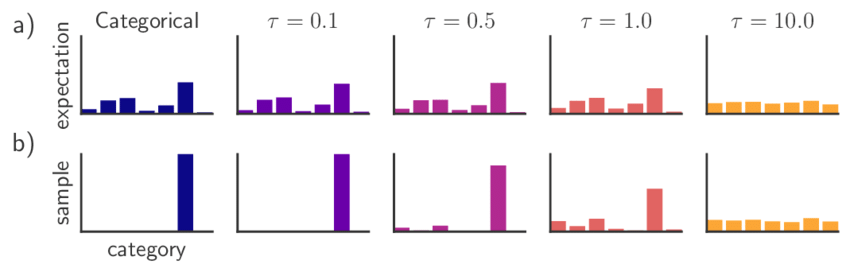

Влияние температуры на $\mathrm{Softmax}$ | [Источник](https://arxiv.org/abs/1611.01144)

#### Связь логитов и вероятностей

Выше мы обсудили, что можно просто считать вторую норму между логитами, а можно KL-дивергенцию после $\mathrm{Softmax}$. Возникает вопрос, как связаны эти два способа и связаны ли они вообще. Проделаем рассуждения из секции 2.1 [статьи](https://arxiv.org/abs/1503.02531).

Для начала рассмотрим кросс-энтропию $C = \sum_i p^T_i(x) \log p^S_i(x)$, так как всё что не зависит от **Student** можно выбросить из задачи оптимизации.

Пусть вероятности были получены из $z_i$ логитов Student и $v_i$ логитов Teacher с температурой $\tau$, тогда будет верно:

\begin{align}
&C = \sum_i p^T_i(x) \cdot \log \color{blue}{p^S_i(x)},\\
&C = \sum_i p^T_i(x) \cdot \log \color{blue}{\frac{e^{\frac{z_i}{\tau}}}{\sum_j e^{\frac{z_j}{\tau}}}},\\
&C = \sum_i p^T_i(x) \cdot \bigl[ \log e^{\frac{z_i}{\tau}} - \log \sum_j e^{\frac{z_j}{\tau}} \bigr].
\end{align}

Теперь посмотри чему равен градиент, нам будет проще посмотреть сначала частную производную по $z_i$.

\begin{align}
&C = \sum_i p^T_i(x) \cdot \bigl[ \frac{z_i}{\tau} - \log \sum\limits_j e^{\frac{z_j}{\tau}} \bigr],\\
&\frac{\partial C}{\partial z_i} = p^T_i(x) \cdot \bigl[ \frac{1}{\tau} - \color{blue}{\frac{e^{\frac{z_i}{\tau}}}{\sum\limits_j e^{\frac{z_j}{\tau}}}} \frac{1}{\tau} \bigr],\\
&\frac{\partial C}{\partial z_i} = \frac{1}{\tau} \bigl[ p^T_i(x) - \color{blue}{p^S_i(x)} \bigr] = \frac{1}{\tau} \bigl[ \frac{e^{\frac{v_i}{\tau}}}{\sum\limits_j e^{\frac{v_j}{\tau}}}  - \frac{e^{\frac{z_i}{\tau}}}{\sum\limits_j e^{\frac{z_j}{\tau}}}  \bigr].
\end{align}

Упростим ещё, для этого воспользуемся разложением $e^{\frac{v_j}{\tau}}$ в Тейлора до второго порядка малости, то есть чем выше $\tau$ тем точнее аппроксимация.

\begin{align}
&\frac{\partial C}{\partial z_i} \approx \frac{1}{\tau} \bigl[ \frac{1 + \frac{v_i}{\tau}}{N + \sum\limits_j \frac{v_j}{\tau}}  - \frac{1 + \frac{z_i}{\tau}}{N + \sum\limits_j \frac{z_j}{\tau}}  \bigr],
\end{align}
где $N$ отвечает за число классов. 

Мы знаем, что результат операции $\mathrm{Softmax}$ не поменяется если мы вычтем из всех логитов какую-либо константу. Поэтому на самом деле, мы можем ещё упростить и представить, что мы рассматриваем центрированный $\mathrm{Softmax}$. Центрированный Softmax означает, что $\sum_i z_i = \sum_i v_i = 0$ (мы всегда из логитов можем вычесть среднее и тем самым центрировать их). С использованием этого предположения мы получим:

\begin{align}
&\frac{\partial C}{\partial z_i} \approx \frac{1}{\tau} \bigl[ \frac{1 + \frac{v_i}{\tau}}{N}  - \frac{1 + \frac{z_i}{\tau}}{N}  \bigr],\\
&\frac{\partial C}{\partial z_i} \approx \frac{1}{\tau^2 N} \bigl[ v_i  - z_i \bigr],\\
\end{align}

#### <font color='Orange'>**Вопрос:**</font> На градиент какой функции похож градиент кросс-энтропии в предположении о центрирование логитов?
Ответ:

С точностью до константы $\frac{1}{\tau^2 N}$ градиент кросс-энтропии совпадает с $\frac{1}{2}\|z - v\|_2^2$. Из этого мы получили 2 важных факта:

1) В предположении центрированного $\mathrm{Softmax}$ обучение на KL-дивергенцию и матчинг логитов эквивалентно с точки градиентной оптимизации;

2) Если мы меняем температуру $\tau$ в 2 раза, то градиенты меняются в 4 раза. Поэтому чтобы градиенты не затухали при высокой температуре и всегда были одного масштаба принято умножать KL-дивергенцию на $\tau^2$. Не забывайте это делать! Это особенно важно, так как часто на практике вы обучаете на функцию потерь вида $(1 - \alpha) \cdot \mathcal{L}_{hard} + \alpha \cdot \mathrm{KL}[p^T \| p^S]$, где $\alpha$ гиперпараметр.

####

На практике, оказывается так, что модель **Student** обученная на **Teacher** действительно начинает повторять поведение **Teacher**. Стандартный пример, посмотреть на карту активаций класса:

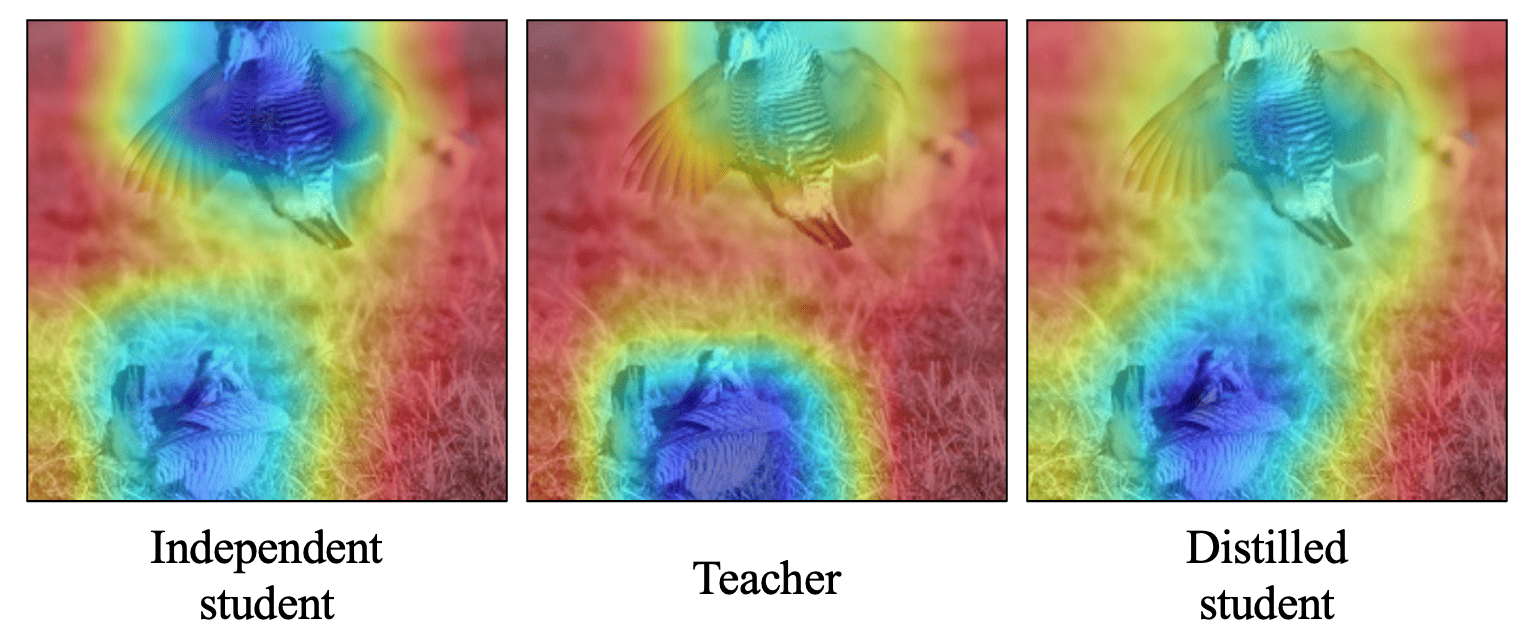

Class activation map (CAM) | [Источник](https://arxiv.org/abs/2205.16004)

Пример дистилляция классификаторов можно посмотреть в [туториале PyTorch](https://docs.pytorch.org/tutorials/beginner/knowledge_distillation_tutorial.html).

#### <font color='Orange'>**Вопрос:**</font> Как вы думаете, как вы думаете, что еще можно учесть из модели Teacher? Допустим, Teacher и Student имеют одну архитектуру, но разное число слоев.

Ответ:

Можно связать промежуточные слои. Называется такой подход был предложен в [Adriana Romero et al., 2014](https://arxiv.org/abs/1412.6550), примерно 7000 цитирований.

### Дистилляция BERT: DistilBERT (2019)

[Victor Sanh et al., 2019](https://arxiv.org/abs/1910.01108), примерно 14000 цитирований

Отличный пост про дистилляцию и DistilBERT в [Учебнике по ML Яндекса](https://education.yandex.ru/handbook/ml/article/distillyaciya-znanij).

DistilBERT &ndash; модель, которая сохраняет 97% качества модели BERT, при этом использует на 40% меньше параметров и требует на 60% меньше времени при применении. Всё благодаря **дистилляции**!


Что применили?

- Архитектура **Student** такая же как и у **Teacher**, но в 2 раза меньше слоев;
- Инициализация слоев **Student** весами из **Teacher** (бывает трудно сделать на практике, но это повышает качество);
- Оставили обучение на задачу маскирования, без задачи next sentence prediction (NSP);
- Функция потерь между промежуточными слоями;

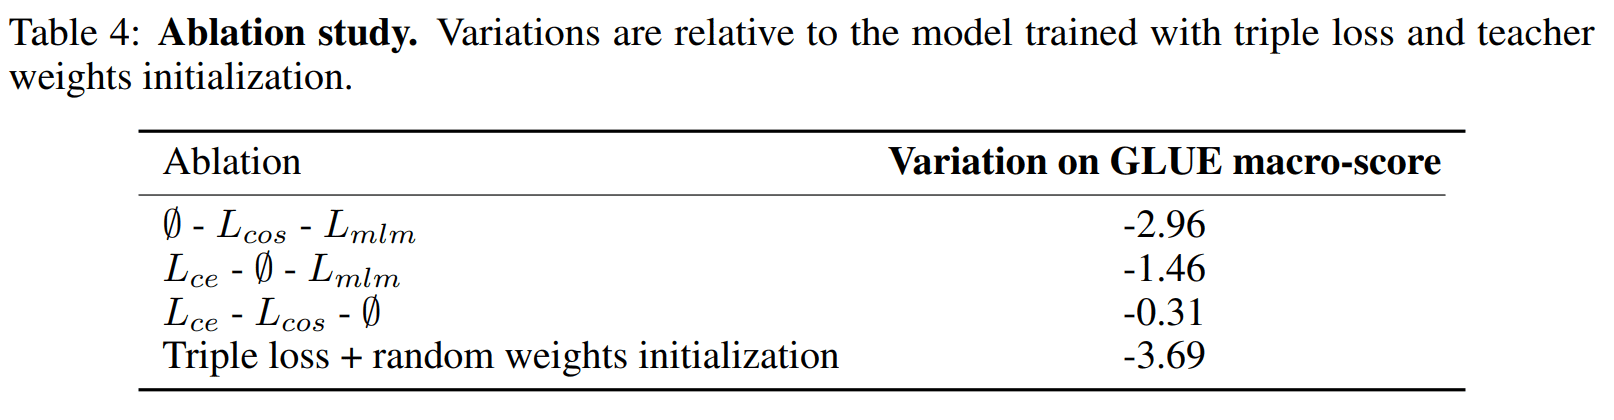

$\mathcal{L}_{ce}$ &ndash; функция потерь исходной задачи (классификация); $\mathcal{L}_{cos}$ &ndash; косинусная схожесть внутренних состояний; $\mathcal{L}_{mlm}$ &ndash; функция потерь задачи маскирования | [Источник](https://arxiv.org/abs/1910.01108)

Из ablation видно, что больше всего влияет инициализация, потом $\mathcal{L}_{ce}$. Меньше всего влияет $\mathcal{L}_{mlm}$.

### Дистилляция без явного учителя: DINO (2021)

[Mathilde Caron et al., 2021](https://arxiv.org/abs/2104.14294), примерно 13000 цитирований

Раньше мы обучали модели для решения конкретных задач: **классификация**, **сегментация**, **детекция**. Иногда так оказывается, что **векторные представления**, полученные с помощью "хорошей модели", намного важнее, чем сама модель. При этом задача получения хорошего векторного представления, которое содержит нужную информацию, более общая, чем конкретная задача.

#### <font color='Orange'>**Вопрос:**</font> Какие модели для получения эмбеддингов слов вы знаете? Какие из них лучше всего сейчас работают?

Ответ:

Если не учитывать классические методы, такие как word2vec и другие, то, скорее всего, BERT и другие трансформерные модели.

####

Большинство современных интересных результатов в области глубокого обучения были получены с помощью трансформеров. Давайте вспомним, что отличает трансформеры от других моделей.

#### <font color='Orange'>**Вопрос:**</font> Благодаря чему трансформерные архитектуры достигают превосходных результатов? Можете считать, что мы сейчас обсуждаем BERT.
Ответ:

Во-первых, архитектура, в частности **механизм внимания** (мы не будем останавливаться на смыслах и интерпретациях). 

Во-вторых, **self-supervised pretraining** (в случае BERT мы решаем задачу маскирования) благодаря которому нам не нужны миллиарды размеченных данных для большой архитектуры.

####

Теперь представим, что стоит задача получения **"хороших" векторных представлений изображений**. Осталось понять, чему должно удовлетворять "хорошее" векторное представление изображения. В общей постановке под "хорошим" можно понимать много разных вещей, например:

- Объекты одного класса были ближе, а разных &ndash; дальше;
- Линейная интерполяция в латентном пространстве делает плавный переход между изображениями.

Мы бы хотели получить такие векторные представления, чтобы **для разных аугментаций одного изображения**, например, размера, изменения разрешения, поворота **получались похожие векторные представления**. Список аугментаций можно расширить до:

1) RandomHorizontalFlip;
2) ColorJitter;
3) RandomResizedCrop;
4) GaussianBlur;
5) Solarization.

Осталось понять, как выучить такую модель. Если мы возьмем изображение и построим по нему разные аугментации, например, одни будут выделять локальные изображения (с RandomResizedCrop), а другие глобальные (без RandomResizedCrop), то мы ожидаем, что модель должна выдавать похожие "хорошие" эмбеддинги. 

#### <font color='Orange'>**Вопрос:**</font> Как вы думаете получить "хороший" эмбеддинг, который совпадает с настоящим изображением проще через локальное или глобальное изображение?

Ответ:

Многое, конечно, зависит от аугментаций, но кажется получить эмбеддинг котенка, проще когда видно и хвост и ушки с лапками. Мы предполагаем, что наши модели умеют извлекать информацию из изображений, даже из глобального контекста, так как мы всё строим на базе трансформерной архитектуры (например ViT).

####

Получается, мы хотим, чтобы вектор $f(x^{\text{local}})$ был похож на $f(x^\text{global})$, где $f(\cdot)$ &ndash; нейросеть, а $x^{\text{local}}$ и $x^\text{global}$ &ndash; соответственно локальные и глобальные изображения.

Похожий метод, только намного аккуратнее и точнее реализован в статье [Emerging Properties in Self-Supervised Vision Transformers](https://arxiv.org/abs/2104.14294).

#### <font color='Orange'>**Вопрос:**</font> Почему нам не подходит **knowledge distillation** в стандартном варианте?
Ответ:

У нас нет модели учителя, мы лишь знаем, что, возможно, задача для $x^\text{global}$ проще и информативнее.

####

Представим, что у нас есть модель **Teacher**, которая хотя бы чуть лучше решает задачу, чем **Student**. Пусть обе нейронные сети имеют одну архитектуру, например, Vision Transformer.

$g_{\theta_s}$ &ndash; модель **Student**,  $g_{\theta_t}$ &ndash; модель **Teacher**.

Для любой модели мы можем выдавать на выходе какой-то вектор для входа $x$, далее мы можем применить $\mathrm{Softmax}$ с температурой и получить распределение вероятностей $P_t(x)$ и $P_s(x)$. Авторы предлагают оптимизировать следующую функцию потерь:


\begin{equation}
    \min_{\theta_s} \sum_{x \in \{x_1^g, x_2^g\}} \sum_{x' \in V, x' \neq x} CE(P_t(x), P_s(x')),
\end{equation}
где $x_1^g$, $x_2^g$ &ndash; глобальные аугментации одного изображения, $V$ &ndash; набор хотя бы двух глобальных изображений и какого-то количества локальных (может быть, даже без них).

Получается, что модель **Teacher** всегда видит только глобальные аугментации (более простые примеры). Остается вопрос, откуда взять модель **Teacher**.

В работе авторы предлагают **knowledge DIstillation with NO labels** или кратко **DINO**, то есть дистилляцию без меток. Алгоритм обучения представлен ниже:

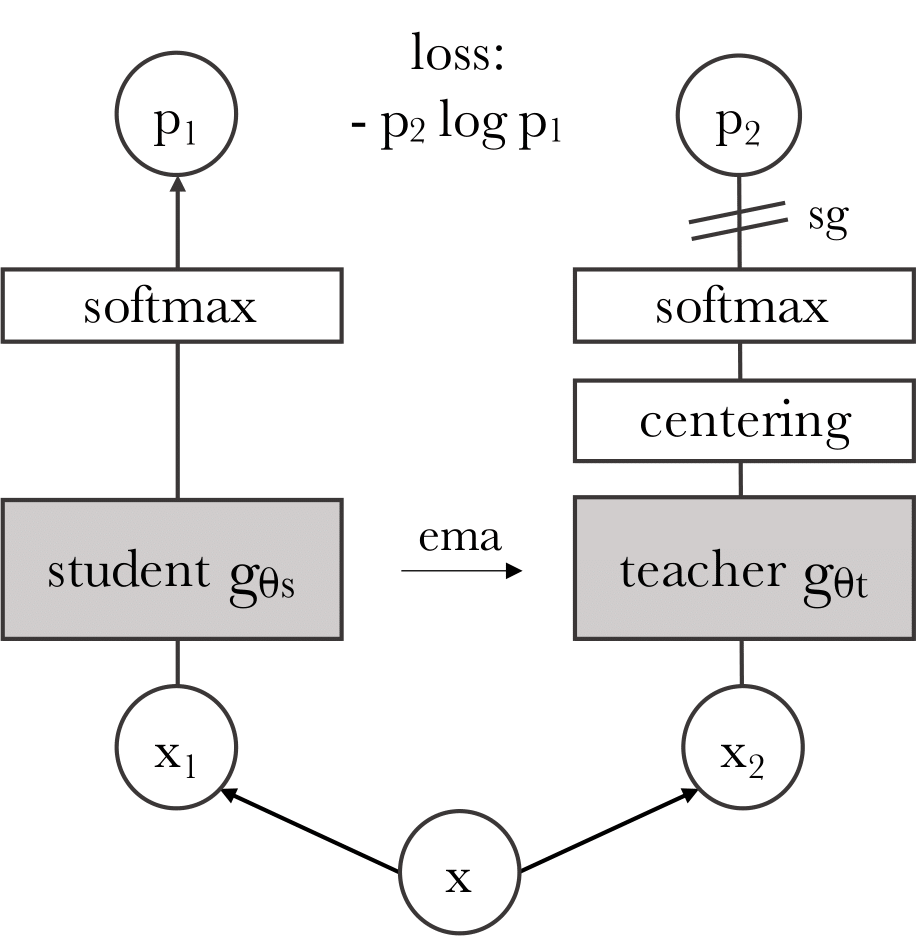

Self-distillation with no labels | [Источник](https://arxiv.org/abs/2104.14294)

Модель **Teacher** видит более простые примеры, кроме того, является EMA-сглаженной версией **Student**, поэтому она всегда чуть лучше. Подход, когда **Teacher** получается из **Student** часто называют самодистилляцией.

Заметим, что у задачи есть наивное решение &ndash; возвращать всегда какую-либо константу. Эту проблему часто называют схлопыванием (collapse). Авторы, ещё отмечают, что схлопывание может возникнуть, когда модель начинает больше учитывать какую-то одну координату. 

То есть мы не хотим получать одинаковый выход, но и не хотим, чтобы в выходе изменялась только одна координата. Для решения этой проблемы есть разные техники. Для борьбы с учётом одной координаты, авторы, предлагают добавлять к выходу модели смещение $c$:
\begin{equation}
    \mathrm{Centering}: g_{\theta_t}(x) = g_{\theta_t}(x) + c.
\end{equation}

$c$ считаем также с EMA-сглаживанием:
\begin{equation}
    c = mc + (1 - m) \frac{1}{B}\sum_{i=1}^B g_{\theta_t}(x_i).
\end{equation}


Для борьбы с одинаковым выходом, авторы подбирают расписание температуры **Teacher**, они берут $\tau_t$ около 0,04 (если взять слишком много, модель схлопнется, взять 0 &ndash; будет плохо учиться). 

Подробный анализ collapse представлен в секции 5.3.

Основные детали:

- $x_1$ и $x_2$ изображения, полученные с помощью различных аугментаций из изображения $x$; 
- Модели учителя и студента имеют одну архитектуру;
- Веса учителя не обучаются и являются EMA-глаженными весами студента;
- **sg** означает stop grad, то есть градиенты не проходят в модель учителя;
- Обучается на кросс-энтропию, так как наша цель, чтобы  ученик был похож по распределению на учителя;
- Важно, что $p_2 \log p_1$, а не наоборот, так как мы учим именно студента;
- Блок centering, центрирует выход teacher с учётом истории на прошлых батчах;
- Низкая температура для учителя (sharpening);
- Датасет ImageNet-1k (1,3 миллиона изображений).

**Напоминание**. EMA-веса модели определяются так: $x_{\text{ema}}^{k + 1} = m \cdot x_{\text{ema}}^{k} + (1 - m) x^{k + 1}$, где $x^k$ веса модели после $k$ итераций обучения. На практике на EMA-весах **очень часто лучше метрики**. В работе [Pavel Izmailov et al., 2018](https://arxiv.org/abs/1803.05407) показывается связь между сглаживанием весов и широким минимумом.

Задача и идея выглядят сложными, но авторы уже выпустили DINOv2, DINOv3 и называют модель DINOv1 &ndash; статьёй с целью Proof of Concept (проверка идеи). Далее мы обсудим DINOv2 и DINOv3.

Реализация DINOv1 при этом аккуратно выполнена и доступна на [GitHub](https://github.com/facebookresearch/dino). 

#### DINOv1 результаты:

Классическим способом оценки моделей, которые извлекают признаки, является обучение какого-то простого классификатора на полученных признаках. Если пространство признаков **"хорошее"**, то даже KNN хватит. Ниже качество классификации ImageNet и сравнение способов выбора учителя:

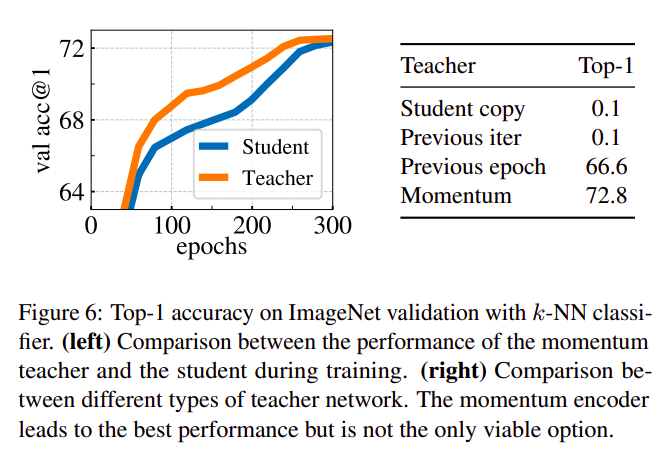

[Источник](https://arxiv.org/abs/2104.14294)

Вспомним ради чего мы все начали, а именно вспомним о задаче сегментации. Естественно в статье множество результатов, но нас интересует именно сегментация. Если мы хотим сегментировать объект, то наша цель выделить все пиксели связанные с ним. Для начала стоит понять, как сегментировать "самый важный" объект на изображении? Для этого стоит посмотреть self-attention для `[CLS]` токена. Пример ниже:

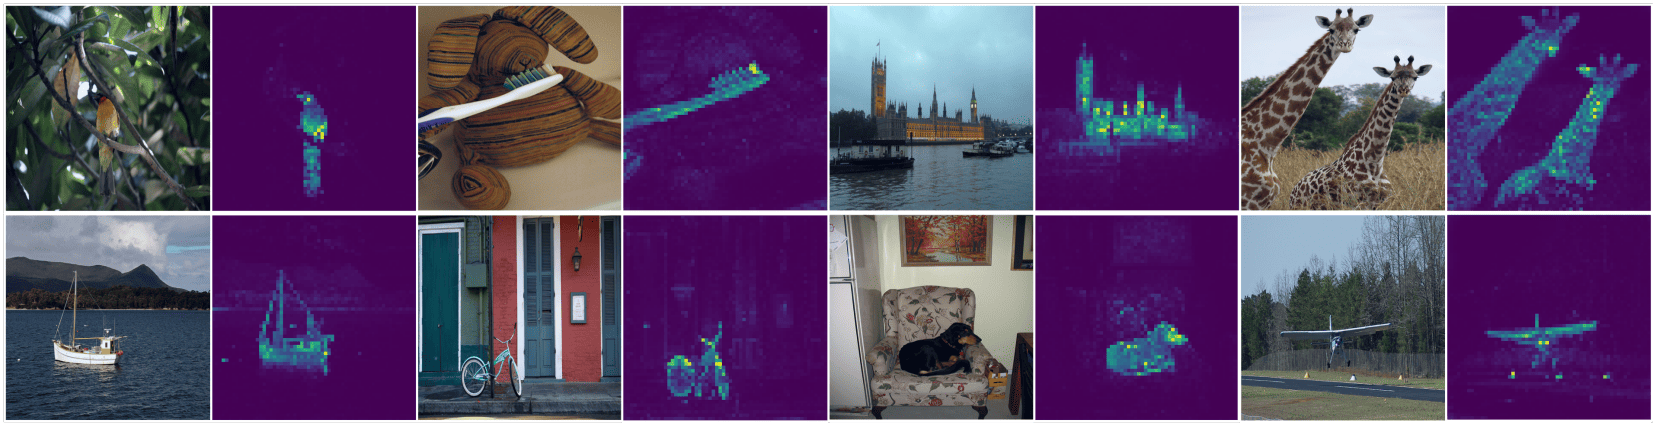

Self-attention from a Vision Transformer with $8\times8$ patches trained with no supervision | [Источник](https://arxiv.org/abs/2104.14294)

При этом если использовать выход self-attention для `[CLS]`, то сегментационная маска получается лучше, чем для некоторых supervised методов.

#### <font color='Orange'>**Вопрос:**</font> Мы знаем, что разные головы attention извлекают разные контексты, как вы думаете как будут выглядеть self-attention для разных голов?
Ответ: 

Должны извлекаться разные части главного объекта или разные главыне объекты.

####

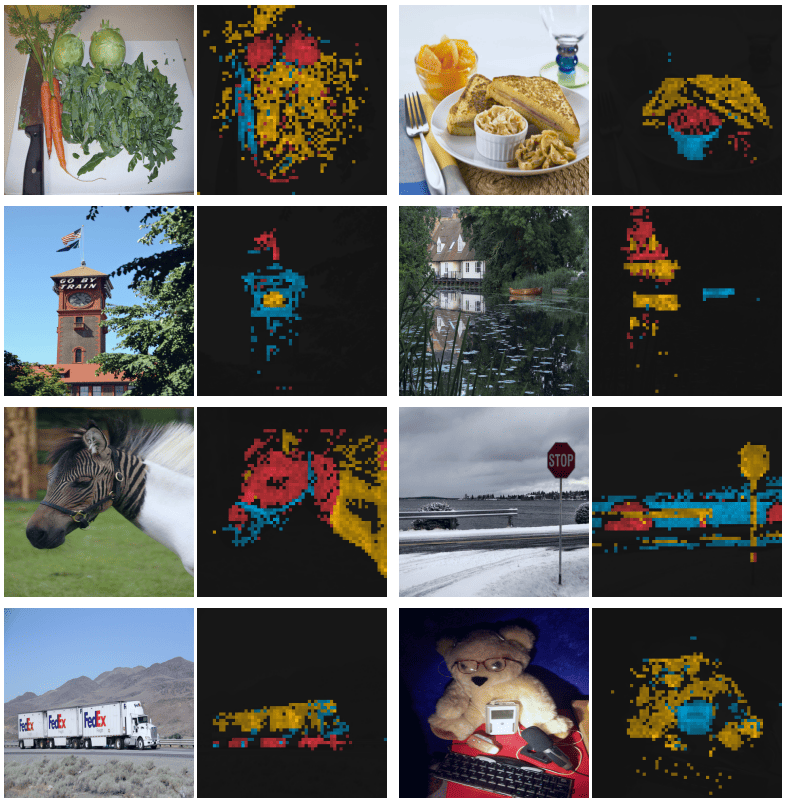

Attention maps from multiple heads | [Источник](https://arxiv.org/abs/2104.14294)

Также мы можем выделить какую-то конкретную точку (патч) и отследить значения в self-attention для нее.

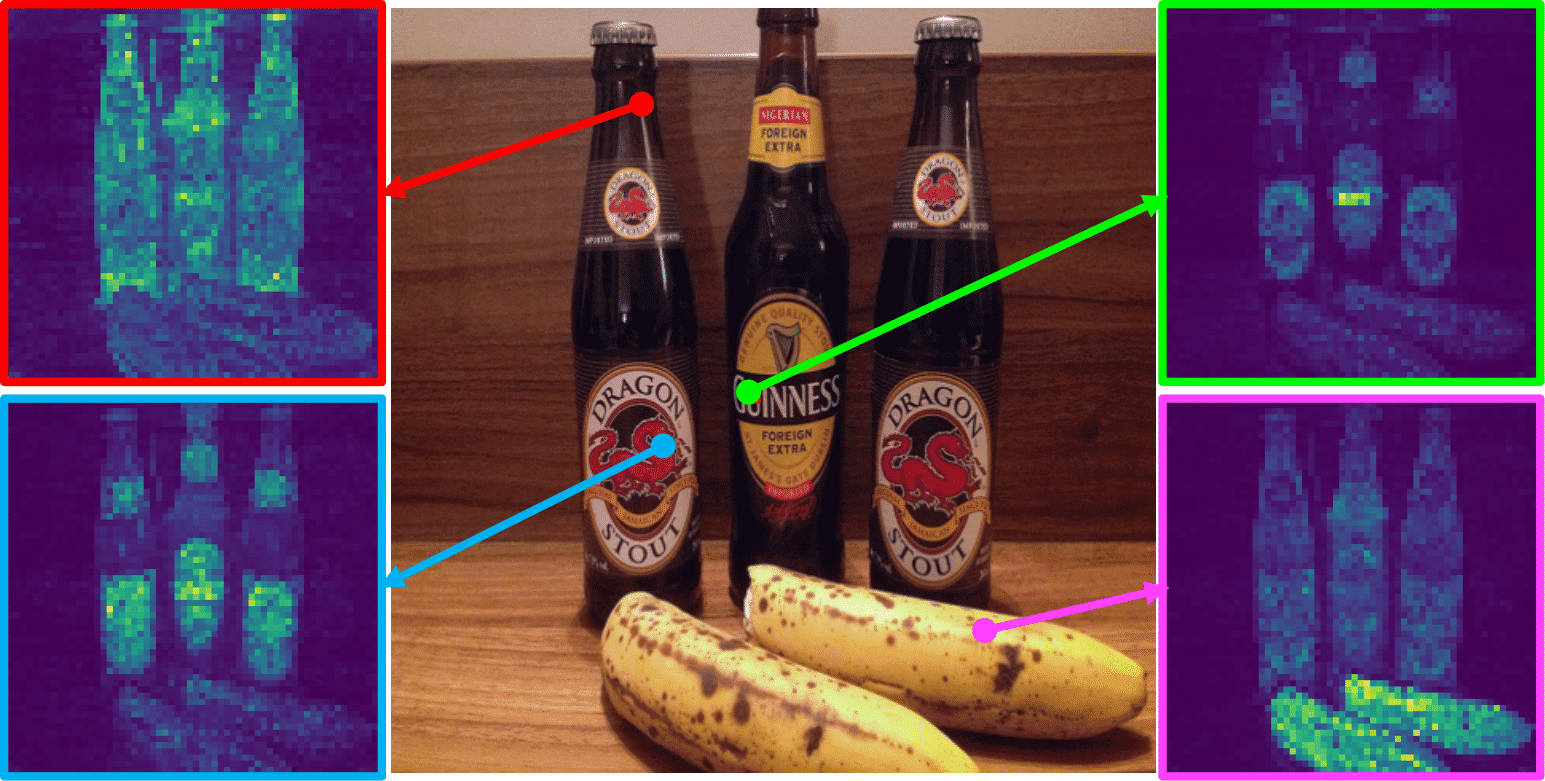

Self-attention for a set of reference points | [Источник](https://arxiv.org/abs/2104.14294)

Подробно про модели DINO можно посмотреть на курсе [Deep Learning 2](https://github.com/thecrazymage/DL2_HSE/tree/102338a347e777f16d1fd64f4e46c6ed732ae9b3/week_07).

**DINOv2**: [Maxime Oquab et al., 2023](https://arxiv.org/abs/2304.07193), примерно 13000 цитирований на октябрь 2026 года и 5000 на октябрь 2025 года.

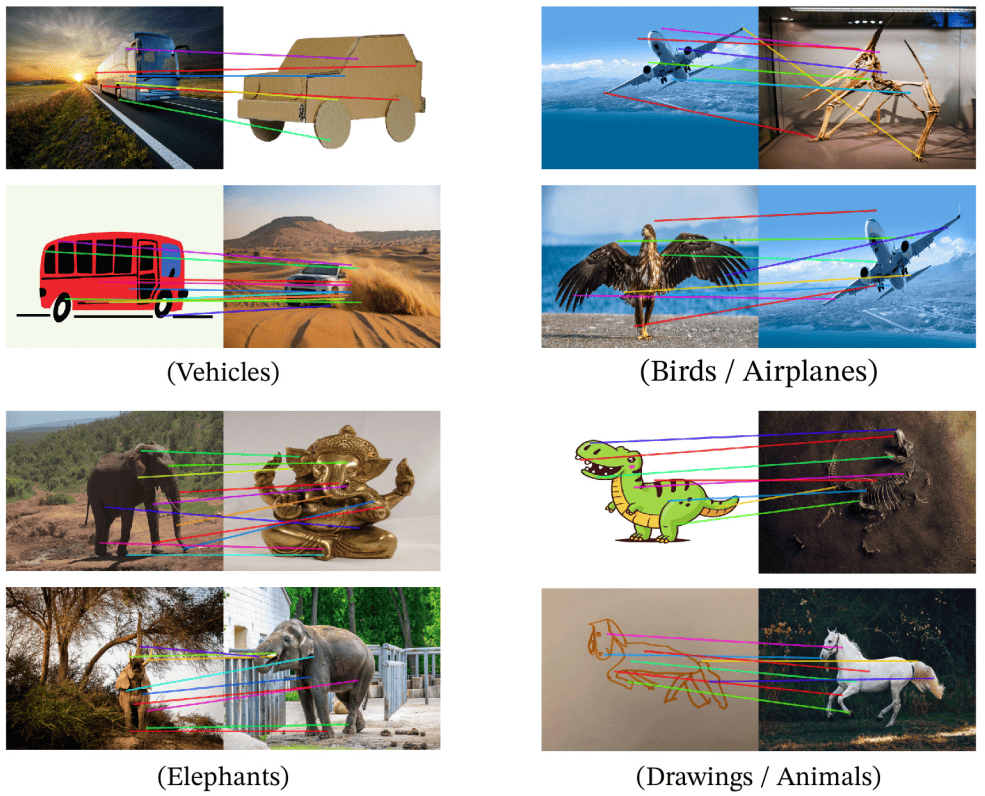

Matching across images | [Источник](https://arxiv.org/abs/2304.07193)

**DINOv3**: [Oriane Siméoni et al., 2025](https://arxiv.org/abs/2508.10104), примерно 1600 цирований; 34 цитирований на момемент 5 октября 2025, дата публикации 13 августа 2025

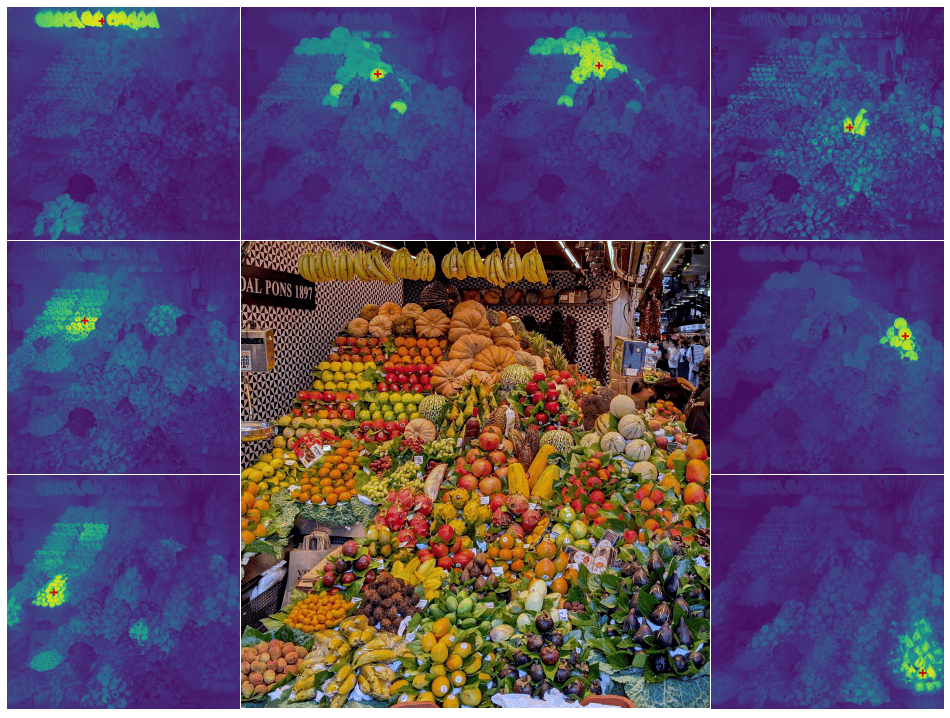

High-resolution dense features | [Источник](https://arxiv.org/abs/2508.10104)

### Дистилляция в диффузионных моделей (2023)

[Axel Sauer et al., 2023](https://arxiv.org/abs/2311.17042), примерно 1100 цитирований

На изображениях возникает своя особенность, например, часто мы не можем повторить большую модель достаточно хорошо и в точности получить её выход, поэтому мы хотим ослабить задачу. Например, матчить не регрессионно, а по распределениям. Для матчинга распределений мы можем использовать состязательное обучение.

Таким образом, мы уже не используем GAN модель для генерации, а используем подход из этой области для дистилляции.

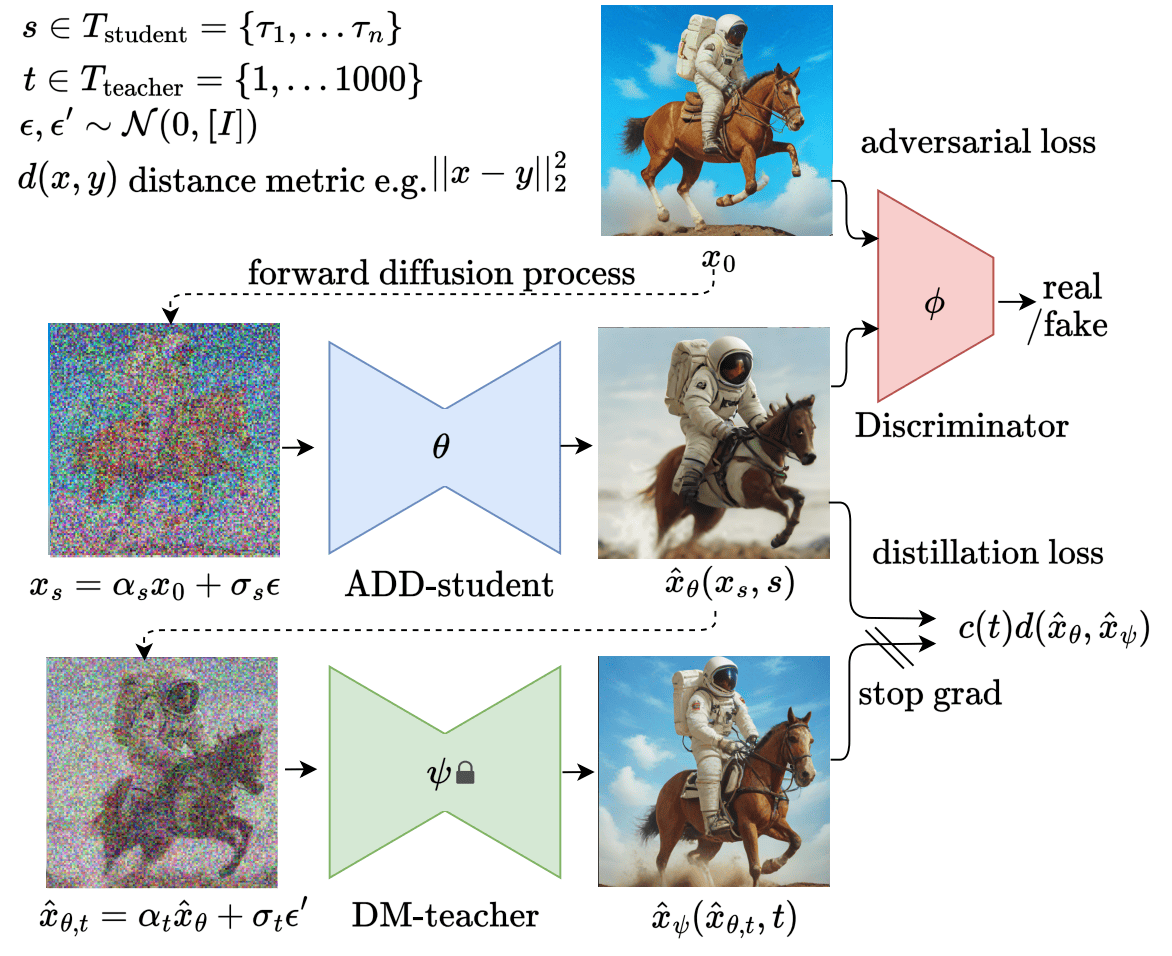

Adversarial Diffusion Distillation | [Источник](https://arxiv.org/abs/2311.17042)

На самом деле, существует много примеров дистилляции для диффузионных моделей: consistency models, progressive distillation и другие. Мы их не рассматриваем, так как там нужно чуть больше знаний о диффузионных моделей. Подробнее можете почитать в оригинальных статьях или узнать на специализированных курсах, например, [Генеративные модели на основе диффузии](http://wiki.cs.hse.ru/%D0%93%D0%B5%D0%BD%D0%B5%D1%80%D0%B0%D1%82%D0%B8%D0%B2%D0%BD%D1%8B%D0%B5_%D0%BC%D0%BE%D0%B4%D0%B5%D0%BB%D0%B8_%D0%BD%D0%B0_%D0%BE%D1%81%D0%BD%D0%BE%D0%B2%D0%B5_%D0%B4%D0%B8%D1%84%D1%84%D1%83%D0%B7%D0%B8%D0%B8_(25/26)). 

### Дисстилляция численных методов

[Vinh Tong et al., 2024](https://arxiv.org/abs/2405.15506), примерно 50 цитирований

[Oganov et al., 2025](https://arxiv.org/abs/2510.17699), примерно 0 цитирований

$\newcommand{\bx}{\mathbf{x}} \newcommand{\normalpoint}[3]{\mathcal{N}\left(#1 \ | \ #2, #3\right)} \newcommand{\kl}[2]{D_{\mathrm{KL}}\!\left(#1 ~ \| ~ #2\right)} \newcommand{\normal}[2]{\mathcal{N}\left(#1, #2\right)} \newcommand{\dd}{\mathrm{d}} \newcommand{\E}{\mathbb{E}} \newcommand{\by}{\mathbf{y}} \newcommand{\teacher}{\Phi^{\mathcal{T}}} \newcommand{\student}{\Phi^{\mathcal{S}}} \newcommand{\teal}[1]{\textcolor{teal}{#1}}
\newcommand{\redorange}[1]{\color{Orange}{#1}}
\newcommand{\royalblue}[1]{\color{RoyalBlue}{#1}}
\newcommand{\ctheta}{\color{RoyalBlue}{\theta}}
\newcommand{\cphi}{\color{Orange}{\phi}}
\newcommand{\cxi}{\color{teal}{\xi_j}}
\renewcommand{\v}{\boldsymbol{v}}$

Мы знаем, что для большинства ОДУ есть доказательства существования и единственности решения. Допустим у нас есть решение ОДУ с начальным условием $\bx_T$, например, полученное с помощью любого из рассмотренных выше методов. Будем обозначать такое решение за:
\begin{equation}
    \teacher(\bx_T) = \text{ODESolve}\left(\bx_T, \v(\cdot, \cdot), T \rightarrow 0 \mid \text{Schedule, Solver, Params} \right),    
\end{equation}
где $\v(\cdot, \cdot)$ определенное ранее векторное поле, только  теперь считаем, что модель уже обучена. В качестве **Schedule** обозначим сетку дискретизации, **Solver** --- все параметры численной схемы, **Params** --- дополнительные параметры. Важно, что нас не интересует эффективность $\teacher(\bx_T)$, самое главное, что это достаточно хорошее решение.

Представим, что есть эффективная схема, которая требует заданное NFE, назовем её $\student(\bx_T)$:
\begin{equation}
    \student(\bx_T) = \text{ODESolve}\left(\bx_T, \v(\cdot, \cdot), T \rightarrow 0 \mid \text{Schedule}_S, \text{Solver}_S, \text{Params}_S \right). 
\end{equation}

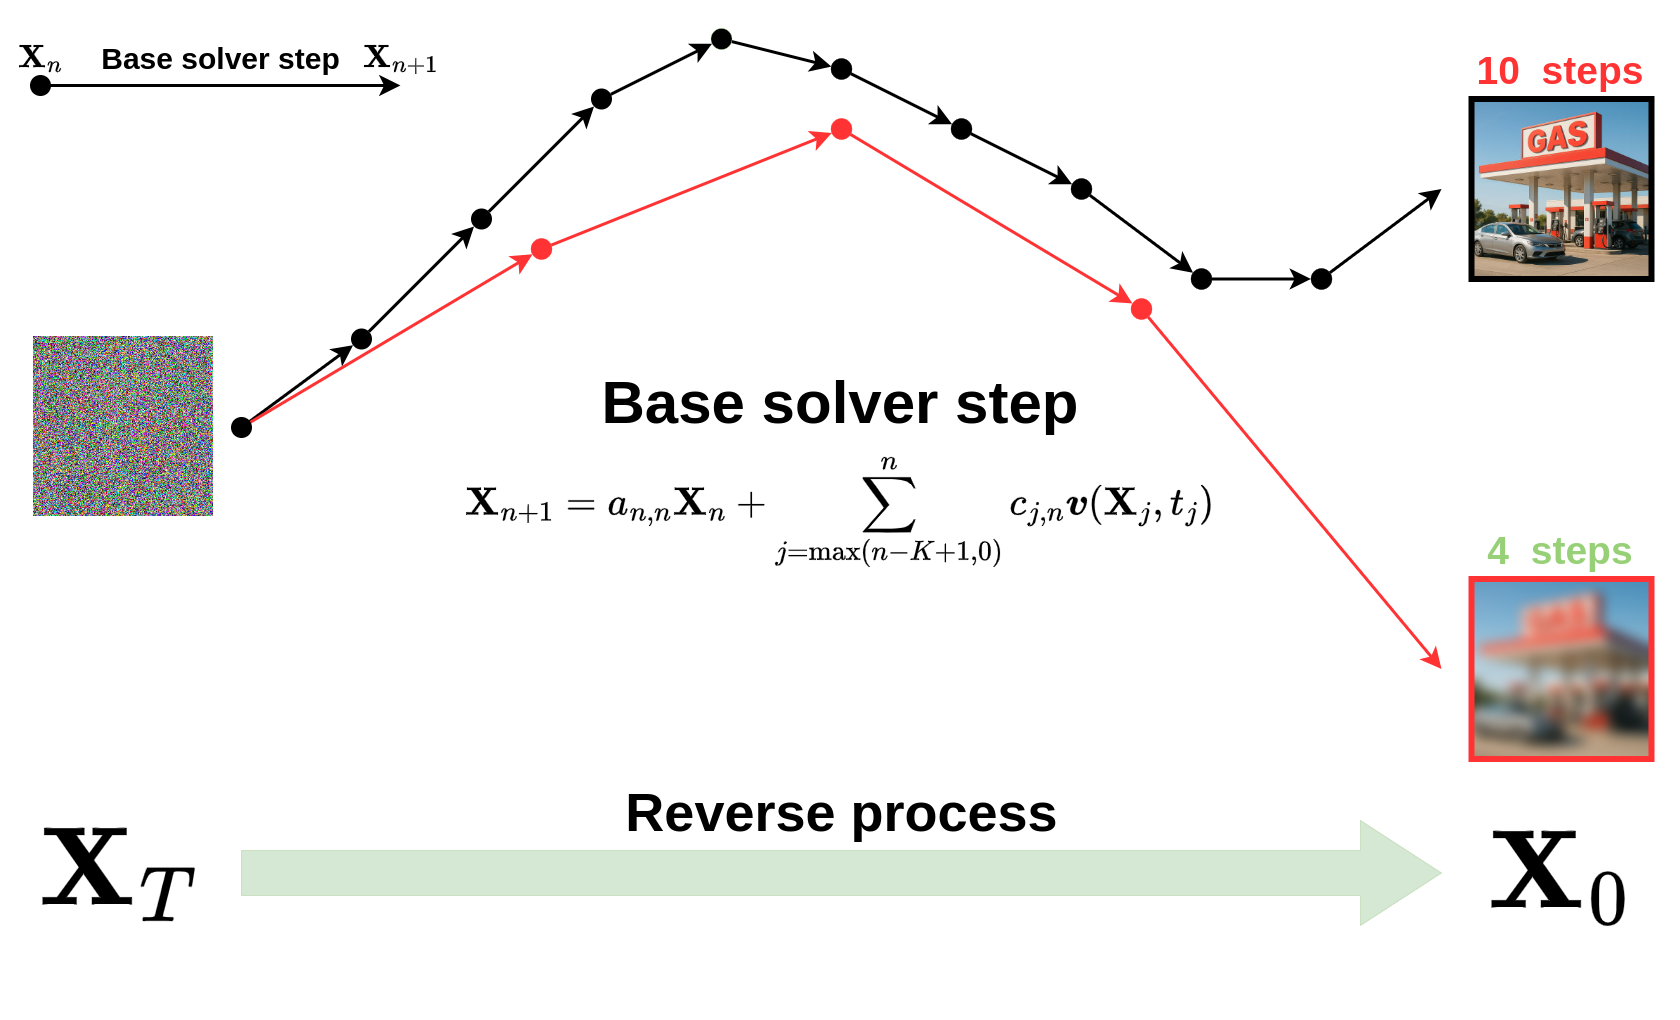

Если мы хотим, чтобы решения через схему $\student$ были на те решения, которые мы считаем правильные $\teacher$, значит нам нужно минимизировать функционал:
\begin{equation}
    \E_z\, \dd(\teacher(z), \student(z)), \quad z \sim \mathcal{N}(0, \mathbf{I}),
\end{equation}
где $\dd(\cdot, \cdot)$ &ndash; расстояние.

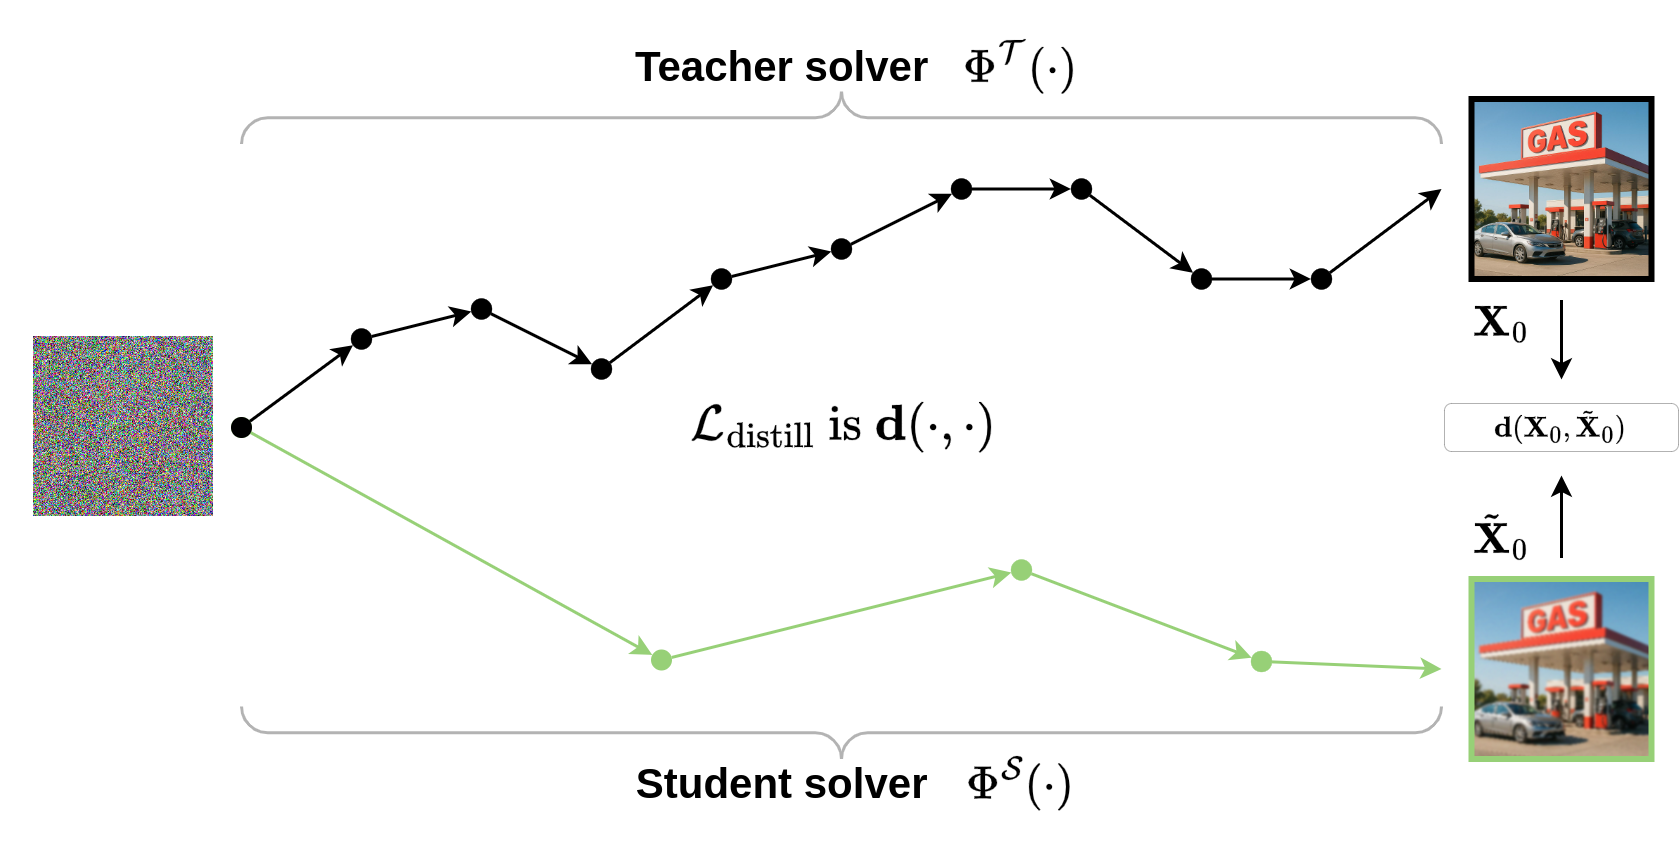

### Дистилляция в LLM: MiniLLM (2023)

[Yuxian Gu et al., 2023](https://arxiv.org/abs/2306.08543), примерно 1200 цитирований

Попробуем посмотреть, как применить методы дисстилляции к LLM. Для этого нам нужен будет следующий факт.

В случае дистилляции классификаторов, мы добавляли $KL[p^T \| p^S]$ и это работало хорошо, в случае генерации текстов на практике это работает плохо. Статья которую, мы будем обсуждать предлагает оптимизировать $KL[p^S \| p^T]$ и авторы показывают, что этот выбор сильно улучшает качество.

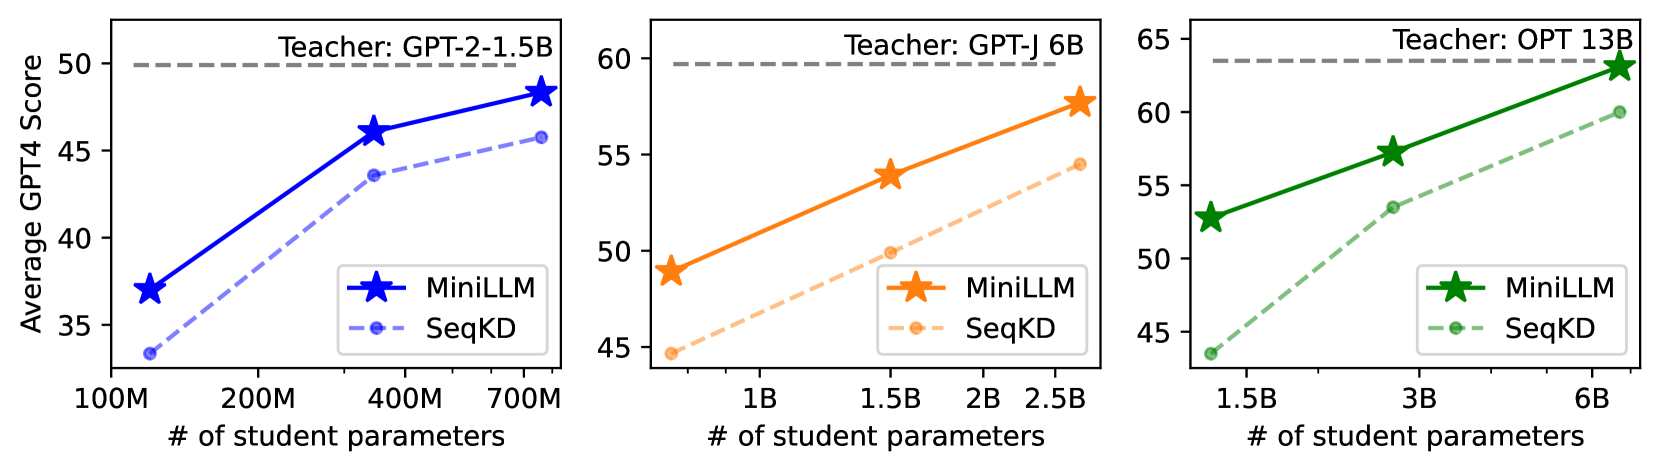

MiniLLM &ndash; метод описанный выше, SeqKD &ndash; обучать на траектории полученные из **Teacher** | [Источник](https://arxiv.org/abs/2306.08543)

#### <font color='Orange'>**Вопрос:**</font>  Почему Forward KL может работать плохо, а Reverse KL справляется с задачей хорошо? 
*Подсказка:* Вспомните про GAN. 

Ответ:

####

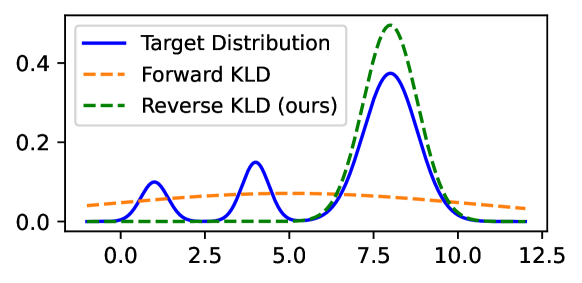

Влияние KL | [Источник](https://arxiv.org/abs/2306.08543)

Такой эффект наблюдается, так как **в классификации** чаще существует **один** подходящий класс. В случае **генерации текста**, часто много мод, так как **продолжить текст** можно разными способами.

Правда возникает проблема, что оптимизация $KL[p^S \| p^T]$ по параметрам $p^S$ значительно труднее, чем например по параметрам $p^T$. Для этого нужно использовать подходы из **reinforcement learning**, так как мы начинаем оптимизировать $\mathbb{E}_{p^S} \log \frac{p^S}{p^T}$. Оптимизируемые параметры есть в функции внутри математического ожидания и в том, по чему берем математическое ожидание. Мы не можем явно применить Монте-Карло оценку градиента. Подробнее узнаете на курсе **Обучение с подкреплением** и курсе **Байесовских Методов**.


У методов reinforcement learning часто долгая сходимость, высокая дисперсия градиентов и много трюков. Мы не будем останавливаться на этом, а представим, что задачу оптимизации $KL[p^S \| p^T]$ мы можем решить (хоть и не тривиально).

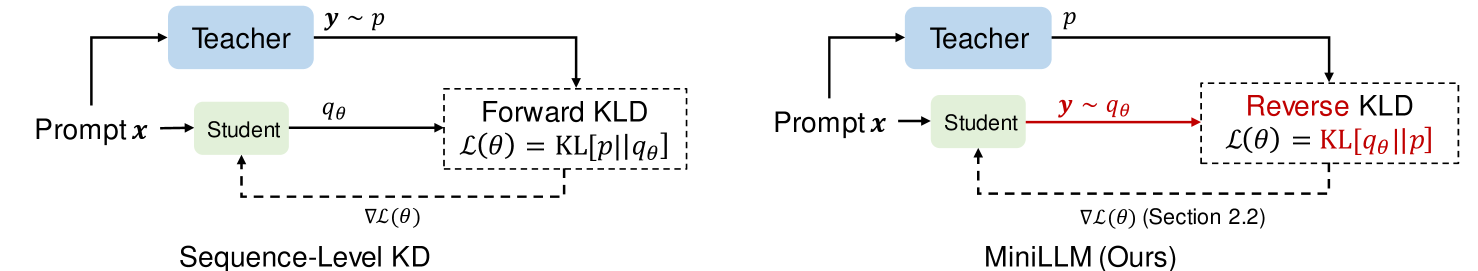

Метод | [Источник](https://arxiv.org/abs/2306.08543)

#### Кратко про обучение MiniLLM (используем базовые знания по RL)

В случаи обучения языковых моделей мы предсказываем следующий токен на основе всех предыдущих, то есть мы оптимизируем функционал:

\begin{align}
\mathbb{E}_{y \sim p^S_{\theta}(y \mid x)} \log \frac{p^S_{\theta}(y \mid x)}{p^T(y \mid x)} \to \min_{\theta},
\end{align}
где $x$ &ndash; контекст, $y$ &ndash; следующий токен. Пока представим, что $y$ это один новый токен.


Мы можем воспринимать $p^S_{\theta}(y \mid x)$ как некоторую обучающую политику. Тогда мы можем обозначить $\log \frac{p^S_{\theta}(y \mid x)}{p^T(y \mid x)}$ за $Q$ функцию для состояния $x$ и действия $a$, а оптимизируемый функционал $V$ функция. 

\begin{align}
V_{\theta}(x) := \mathbb{E}_{y \sim p^S_{\theta}(y \mid x)} Q_{\theta}(x, y) \to \min_{\theta}.
\end{align}

Кроме того, мы знаем, что политика дифференцируема по $\theta$, а значит:

\begin{align}
\nabla_{\theta} V_{\theta}(x) = \mathbb{E}_{y \sim p^S_{\theta}(y \mid x)} \bigl[\nabla_\theta \log p^S_{\theta}(y \mid x) Q_{\theta}(x, y) + \nabla_{\theta} Q_{\theta}(x, y) \bigr].
\end{align}

Далее мы можем стандартно расписать $Q$ через $Q$ и $V$ через $V$. Нас же интересует оптимизация когда $y$ это **не один токен**, а **последовательность** сгенерированная с помощью **Student** (политики). Тогда можно воспользоваться Policy Gradient Theorem (прочитать можно в  Reinforcement Learning Textbook [Sergey Ivanov, 2022](https://arxiv.org/abs/2201.09746)).

У такого подхода будет высокая дисперсия стохастических градиентов и он будет плохо учиться, поэтому, как часто бывает в RL, авторы используют разные трюки:

- Single-Step Decomposition: Разбить функцию награды на награду на первом шаге и на всех последующих. К награде для всех будущих шагов применить Length Normalization;

- Teacher-Mixed Sampling: семплировать следующий токен не только из Student, а из смеси выходов Student и Teacher;

- Length Normalization: нормализацию на длину $y$.

Цель данной секции продемонстрировать специфику дистилляции в обучении LLM.

## Спекулятивное декодирование (Speculative Decoding)

### Fast Inference from Transformers via Speculative Decoding (2022)

[Yaniv Leviathan et al., 2022](https://arxiv.org/abs/2211.17192), примерно 2500 цитирований

[Блог-пост от Google Research](https://research.google/blog/looking-back-at-speculative-decoding/)

Выше мы научились дистиллировать большие модели в маленькие и знаем, что этот способ применим LLM и он работает! 

На самом деле, трансформеры сами по себе **хорошо масштабируемы**, поэтому очень часто у нас есть **small**, **middle** и **large** версии моделей с одной архитектурой. Например, small имеет 1 млрд параметров, а large может все 70 млрд. 

Возникает вопрос, как использовать все, что мы прошли на практике для решения прикладной задачи, а именно появляется вопрос:

**Как ускорить генерацию текста с помощью LLM?**

Сделаем 2 важных наблюдения:

- Есть **простые** токены, а есть **сложные**. Например, чтобы продолжить текст "У лукоморье дуб зелёный ...", нам не нужна большая модель. В случае текста "Интеграл икс по dx от -1 до 5 будет равен ..." следующий токен может быть трудный для маленькой модели, но понятен для большой модели.

- Современные LLM, а в частности блоки трансформеров, **быстро считаются и параллелятся, но требуют огромной памяти** в случае очень больших моделей. Если мы подгрузим слой трансформера в память, то мы у нас будет достаточно много ресурсов запускать его параллельно. Основная проблема в подгрузке слоя.

### Speculative execution

Для начала упростим задачу и представим процесс авторегрессионный генерации следующим способом:
    
\begin{equation}
x^{k+1} = f(x^k),
\end{equation}
где функция $f$ хорошо параллелится, но сама по себе долго вычисляется. Кроме того у функции $f$ есть хорошая аппроксимация $g$, которая быстро вычисляется.

#### <font color='Orange'>**Вопрос:**</font> Как вы будете генерировать последовательность $x^k$ быстро?

Ответ:

Попробуем сгенерировать всю последовательность через $g$, это сделать можно очень быстро. Получим:

\begin{align}
\hat{x}^0 &= x^0,\\
\hat{x}^{k+1} &= g(\hat{x}^k).
\end{align}

Далее параллельно будем проверять на равенство $\hat{x}^{k+1} = f(\hat{x}^k)$.

Если равенство выполнено всегда, то значит аппроксимация всегда хорошо сработала и $\hat{x}^{k} \equiv x^{k}$.

Если где-то случилось отличие, то значит в этом месте мы сломались и надо честно посчитать функцию. Пусть это будет в момент $n$, тогда повторяем идею для $\hat{x}^n = x^n$.


Такой подход называется [Speculative execution](https://en.wikipedia.org/wiki/Speculative_execution). 

### Speculative sampling

Выше мы немного упростили задачу, так как генерация токенов это недетерминированный алгоритм, а процесс семплирования:

\begin{equation}
x^{k+1} \sim f(x^k).
\end{equation}

Мы можем повторить те же рассуждения, но теперь нам нужно проверять не точное равенство, так как проверять равенство случайных величин не очень здравая идея. Нам нужно чтобы распределения из аппроксимации $g$ и настоящий $f$ совпадали.

#### Rejection Sampling

Рассмотрим сначала более простой для понимания алгоритм Rejection Sampling, подробнее он рассмотрен на лекции по методом сэмплирования на курсе Байесовских методов машинного обучения. Для ознакомления можно обратиться к [конспекту](https://github.com/bmml-team/bmml_ftda/blob/main/Lectures/lecture_4.pdf).

Наша задача получить сэмплы из распределения $p(\cdot)$, однако мы умеем получать сэмплы только из $q(\cdot)$. Метод работает на предположении, что существует такое $с$, что $\forall x \in \mathcal{X}$ выполнено $p(x) < сq(x)$.

Обратите внимание, что в случае конечного множества $\mathcal{X}$ такое $с$ всегда можно найти, в случае бесконечного &ndash; не всегда (пример $p$ &ndash; Коши, $q$ &ndash; Нормальное).

Будем принимать точку, сгенерированную из $q(x)$, только с определённой вероятностью, отражающей приближение. 

Запишем формально: $y \sim q(y),\; \xi \sim \mathbf{U}[0, cq(y)] \Rightarrow \text{accept } y \text{ если } \xi < p(y)$

Докажем, что схема работает:

Фактически, мы утверждаем, что если $x$ &ndash; следующая точка выборки, а $y \sim q(x)$, то мы примем $y$ в качестве следующего сэмпла с вероятностью $\frac{p(y)}{cq(y)}$. Иначе мы можем повторить процедуру, но в нашем случае, мы уже посчитали $p(\cdot)$ и можем честно сэмплировать из этого распределения.

Запишем это как: 

\begin{gather}\label{eq:accept}
\mathbb{P}(\text{accept}) = \mathbb{E}_y \mathbb{P}(\text{accept} \mid y)= \int \frac{p(y)}{cq(y)} q(y)dy = \frac{1}{c}
\end{gather}

Причём, чем ближе распределение $q(\cdot)$ к распределению $p(\cdot)$, тем меньше мажорирующая константа $c$, тем эффективнее работает схема &ndash; будет приниматься больше сэмплов.

Следовательно, 
\begin{gather}\label{eq:RS_proof}
\mathbb{P}(y \mid \text{accept}) = \frac{\mathbb{P}(\text{accept} \mid y) \mathbb{P}(y)}{r(\text{accept})} = \frac{\frac{p(y)}{cq(y)}q(y)}{\frac{1}{c}} = p(y).
\end{gather}

Мы показали, что те сэмплы, которые мы приняли, будут иметь нужное распределение $p(y)$.

Как видно из формул, качество приближения определяется отношением площадей под плотностями, которое равно $\frac{1}{c}$. Метод будет работать хорошо, если будет мало отклонений ($c \approx 1$), и если $c$ будет большим, то необходимо будет больше точек для приближения или же вероятность отказа будет большой. 

#### Speculative sampling доказательство

Авторы предлагают следующий алгоритм:
    
1) Сэмплируем $x \sim q(x)$;

2) Если $q(x) \leq p(x)$, то принимаем $x$;

3) Иначе мы отказываемся с вероятностью $1 - \frac{p(x)}{q(x)}$;

4) В случае отказа мы сэмплируем из распределения $p'(x) = \mathrm{norm}\bigl(\max(0, p(x) - q(x))\bigr)$, где $\mathrm{norm}(z) = \frac{z}{\sum_z' z'}$, что нужно, чтобы $p'(\cdot)$ суммировалось в единицу.

Теперь нам нужно понять, что эта процедура действительно будет давать сэмплы из распределения $p(x)$, кроме того, мы бы хотели, чтобы она давала нам вероятность принятия больше, чем Rejection sampling.


Запишем следующие важные вероятности:

\begin{gather}
\mathbb{P}(\text{accept} \mid x) = \begin{cases}
    1, \text{если } q(x) \leq p(x);\\
    \frac{p(x)}{q(x)},  \text{иначе}.
\end{cases}
\end{gather}

Обратим внимание, что $\mathbb{P}(\text{accept} \mid x) = \min(1,\frac{p(x)}{q(x)})$.

Откуда мы можем найти вероятность принятия:

\begin{gather}
\mathbb{P}(\text{accept}) = E_{q(x)} \mathbb{P}(\text{accept} \mid x) = \sum_{x'} q(x') \min(1,\frac{p(x')}{q(x')}) = \sum_{x'} \min(q(x'),p(x')).
\end{gather}

Авторы в статье обозначают величину за $\sum_{x'} \min(q(x'),p(x'))$ за $\beta$.

Значит вероятность отказа (rejection):

\begin{gather}
\mathbb{P}(\text{rejection}) = 1 - \mathbb{P}(\text{accept}) = 1 - \beta.
\end{gather}

Обратим внимание, что $x$ при условии rejection имеют распределение $p'(x)$, значит мы можем найти распределение $x$ по правилу полной вероятности:

\begin{equation}
\mathbb{P}(x) = \mathbb{P}(x, \text{accept}) + \mathbb{P}(x, \text{rejection}) = \mathbb{P}(\text{accept} \mid x) q(x) + \mathbb{P}(\text{rejection} \mid x) p'(x).
\end{equation}

\begin{equation}
\mathbb{P}(x) =  q(x) \min(1,\frac{p(x)}{q(x)}) + (1 - \beta) p'(x) = \min(q(x), p(x)) + (1 - \beta) \mathrm{norm}\bigl(\max(0, p(x) - q(x))\bigr).
\end{equation}

Осталось заметить, что:

\begin{equation}
    \mathrm{norm}\bigl(\max(0, p(x) - q(x))\bigr) = \frac{\max(0, p(x) - q(x))}{\sum_{x'} \max(0, p(x') - q(x'))} = \frac{p(x) - \min(p(x), q(x))}{\sum_{x'} p(x') - \min(p(x'), q(x'))} = \frac{p(x) - \min(p(x), q(x))}{1 - \beta},
\end{equation}
так как $\max(0, p(x) - q(x)) = p(x) - \min(p(x), q(x))$, значит:
\begin{equation}
\mathbb{P}(x) = \min(q(x), p(x)) + (1 - \beta) \frac{p(x) - \min(p(x), q(x))}{1 - \beta} = p(x).
\end{equation}

Получается алгоритм действительно дает сэмплы из распределения $p(x)$.

#### Сравнение Rejection sampling и Speculative sampling 

Сравним вероятность принятия двух методов.

В случае rejection sampling и конечного множества мы можем выбрать $c = \max{\frac{p(x)}{q(x)}}$, а значит вероятность принятия:
    
\begin{equation}
\mathbb{P}(\text{accept}) = \mathbf{E}_q(x) \frac{p(x)}{cq(x)} = \sum_x p(x) \frac{1}{\max{\frac{p(x')}{q(x')}}} = \sum_x p(x) \min{\frac{q(x')}{p(x')}}
\end{equation}

Попробуем оценить её сверху, заметим, что $\min{\frac{q(x')}{p(x')}} \leq \min(1, \frac{q(x)}{p(x)})$ для любого $x$, значит:

\begin{equation}
\mathbb{P}(\text{accept}) = \sum_x p(x) \min{\frac{q(x')}{p(x')}} \leq \sum_x p(x) \min(1, \frac{q(x)}{p(x)}) = \sum_x \min(q(x), p(x)),
\end{equation}
что является вероятностью принятия для speculative sampling.

Подробный вывод и сравнение в Appendix A.

#### Speculative decoding алгоритм

Подробный псевдокод алгоритма описан ниже, $n$ &ndash; первый токен, где произошёл отказ, то есть мы сэмплируем из $p'(\cdot)$ и отбрасываем все токены после $n$.

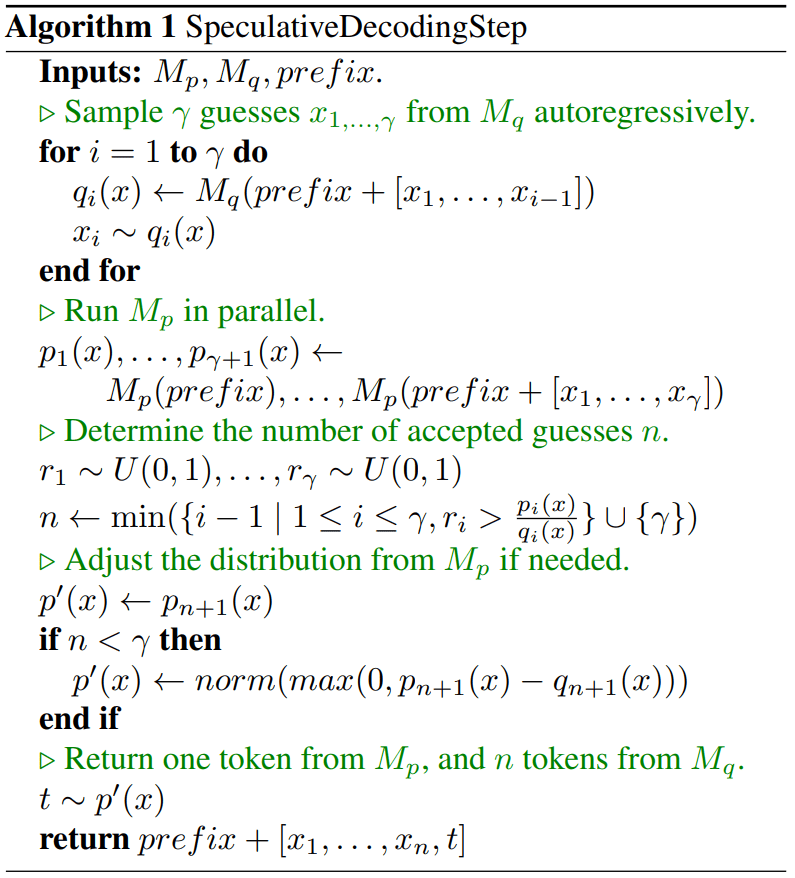

Алгоритм Speculative decoding | [Источник](https://arxiv.org/abs/2211.17192)

### Speculative decoding

[Наглядное видео](https://storage.googleapis.com/gweb-research2023-media/media/SpeculativeDecoding-1-Illustration.mp4)

Если мы генерируем жадно, то нам для генерации текста подойдет `Speculative execution`, если мы каждый раз сэмплируем новый токен, то  `Speculative sampling`. Единственное, что нужно &ndash; это быстрая аппроксимация, которая будет хорошо предсказывать простые токены. Её можно получить либо с помощью дистилляции, либо через масштабирование трансформера.


На практике для ускорения 11B T5-XXL модели для задачи перевода, использовали аппроксимацию маленькой моделью на 60M T5-small и получили ускорение в ~3 раза. [Блог-пост от Google Research](https://research.google/blog/looking-back-at-speculative-decoding/).

[Блог-пост от NVIDIA про современные подходы](https://developer.nvidia.com/blog/an-introduction-to-speculative-decoding-for-reducing-latency-in-ai-inference/)

### EAGLE

[Yuhui Li et al., 2024](https://arxiv.org/abs/2401.15077), примерно 700 цитирований


Основная идея: разделим алгоритм Speculative decoding на два части


1) Draft model, то есть что такое $q(\cdot)$ и то, какие последовательности полученные из Draft model мы потом проверяем с помощью target LLM (та, которую мы ускоряем);

2) Алгоритм правильного сэмплирования, чтобы по итогу получали верное распределение $p(\cdot)$.


Авторы предлагают не менять алгоритм сэмплирования, а именно сохранить speculative sampling.


Авторы меняют draft model и способ построения последовательностей.

#### Draft model

Вместо более маленькой модели, они учат новую модель в пространстве признаков перед LM Head, которая по прошлым признакам и засэмплированному из них токену предсказывает следующие признаки перед LM Head. 


Авторы показывают, что можно обучить маленькую модель на небольшом датасете, которая будет хорошо предсказывать следующий набор признаков. Кроме того, очень важно, чтобы модель видела токен, так как это упрощает обучение. Так как мы предсказываем признаки перед LM Head это задача выходит проще, чем предсказывать сразу распределение токенов.

#### Способ построения последовательностей

Брать последовательности не просто цепочкой, а строить дерево. Так мы повышаем вероятность, что какая-то из последовательностей в дереве будет принята.

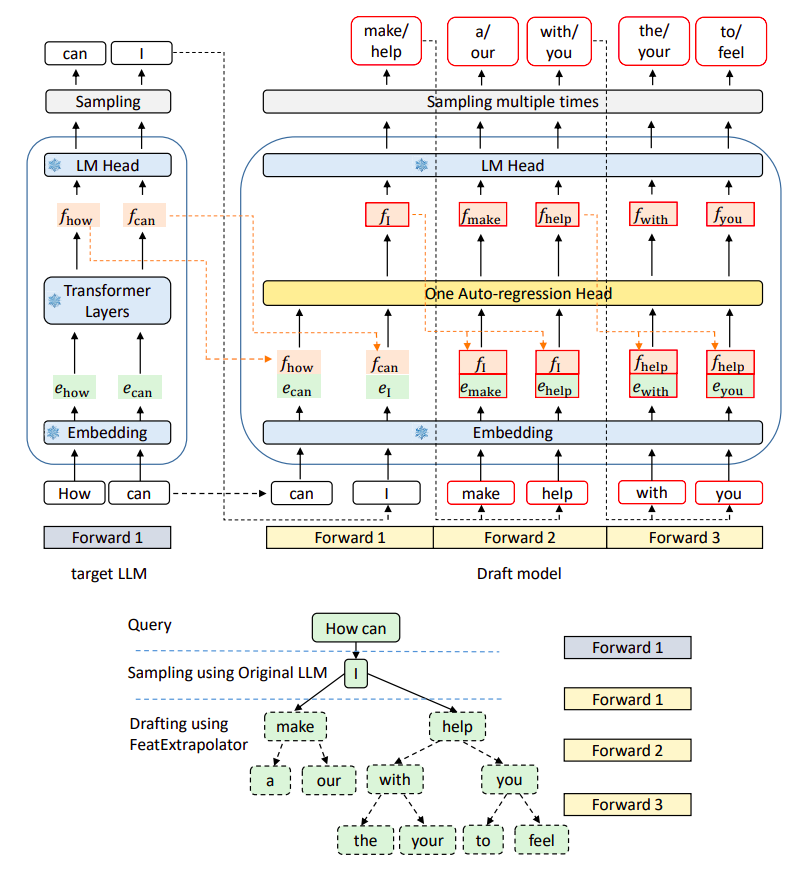

[Источник](https://arxiv.org/abs/2401.15077)

В статье подробно описана процедура обучения и построения дерева. Кроме того, рассказано как реализовать эту процедуру эффективно.

### EAGLE-2

[Yuhui Li et al., 2024](https://arxiv.org/abs/2406.16858), примерно 400 цитирований

Основная идея: строить дерево с разным числом потомков в каждом узле. Выбирать количество узлов в зависимости от сложности получаемой последовательности.

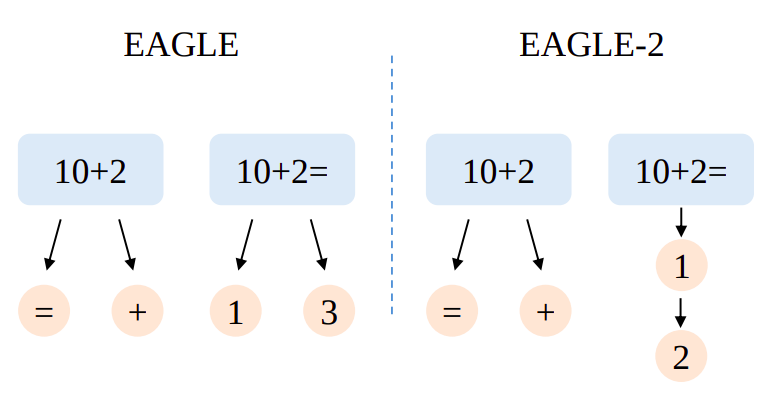

[Источник](https://arxiv.org/abs/2406.16858)

### EAGLE-3

[Yuhui Li et al., 2025](https://arxiv.org/abs/2503.01840), примерно 350 цитирований

Основная идея: использовать draft model, которая принимает признаки не с последнего слоя, а с нескольких последних. В статье подробно описаны нюансы, которые возникают при таком подходе.

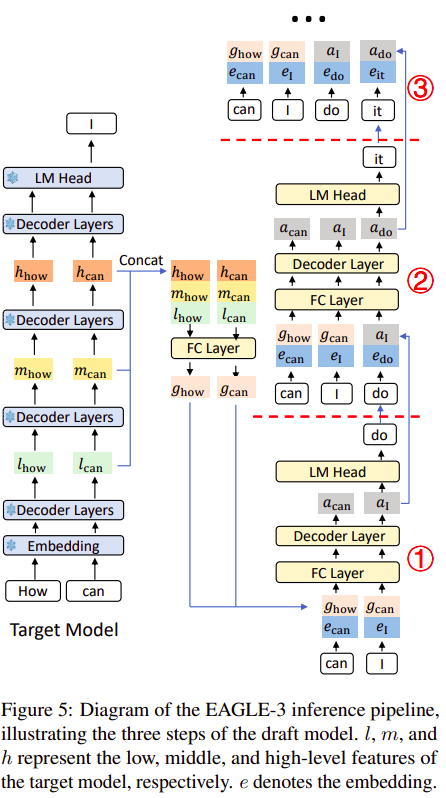

[Источник](https://arxiv.org/abs/2503.01840)

### DFlash

[Jian Chen et al., 2026](https://arxiv.org/abs/2602.06036), примерно 100 цитирований

Как draft model использовать текстовые диффузионные модели, которые генерируют сразу последовательность без авторегрессии. После чего проверять генерацию текстовой диффузии с помощью target LLM.

## Дополнительно может быть интересно

Это список работ, который могут вам интересны, но которые мы не затрагивали выше:


1) Как выбирать архитектуры студента и как они влияют на дистилляцию? [Zhiwei Hao et al., 2023](https://arxiv.org/abs/2310.19444), примерно 100 цитирований

2) Что будет если учить студента и учителя одновременно? [Ying Zhang et al., 2017](https://arxiv.org/abs/1706.00384), примерно 2400 цитирований

3) Если выбрать учителя слишком сильным, то ничего не обучится? [Jang Hyun Cho, Bharath Hariharan, 2019](https://arxiv.org/abs/1910.01348), примерно 982 цитирований

4) Почему иногда студент превосходит учителя? [Tommaso Furlanello et al., 2018](https://arxiv.org/abs/1805.04770), примерно 1390 цитирований

5) Почему задача дистилляции трудная и имеет много локальных минимумов? [Samuel Stanton et al., 2021](https://arxiv.org/abs/2106.05945), примерно 322 цитирований

6) Как перенести Inductive Bias из CNN в MLP и из LSTM в Transformer с помощью дистилляции? [Samira Abnar et al., 2020](https://arxiv.org/abs/2006.00555), примерно 80 цитирований